# 00a — BASELINE · Vol / Risk Regression · stocks

**Job:** `J01_vol_risk` | **Phase:** P1 | **Status:** active

**Architecture:** Ridge on last-day features (trainable linear baseline)

> **Train this notebook first** in each job folder. Models `01a`–`01e` report whether they beat this baseline.

**Project path (WSL):** `~/ai-workspace/experiments/stock-prediction`

**Kernel:** select **`Python (stock-prediction)`** in the kernel picker (register with `bash scripts/install-jupyter-kernel.sh` if missing).

```bash
cd ~/ai-workspace/experiments/stock-prediction
source .venv/bin/activate
```


## 0) Run configuration

`fast_dev` = 200 symbols / 30 epochs (quick tests). `full` = entire universe / 100 epochs.

In [1]:
# --- ML Iteration 2 job config (do not rename without updating scaffold) ---
JOB_ID = "01"
JOB_SLUG = "vol_risk"
ARCHITECTURE = "baseline"
UNIVERSE = "stocks"
ASSET_TYPE = "stock"
TARGET_TYPE = "abs_return"
UNIVERSE_PREFIX = "stocks_universe"
TARGET_SUFFIX = ""

RUN_MODE = "fast_dev"  # "fast_dev" | "full"
FAST_DEV_MAX_SYMBOLS = 200
FORCE_REBUILD_DATA = False
FAST_DEV_EPOCHS = 30
FULL_EPOCHS = 100

processed_dir = None

if RUN_MODE == "fast_dev":
    DATASET_TAG = f"dev{FAST_DEV_MAX_SYMBOLS}"
    sequences_name = f"{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_sequences_plus5.npz"
    config_name = f"pipeline_config_{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_plus5.json"
    scaler_name = f"scaler_{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_plus5.json"
    MODEL_TAG = f"_{DATASET_TAG}"
    TRAIN_EPOCHS = FAST_DEV_EPOCHS
else:
    DATASET_TAG = "full"
    sequences_name = f"{UNIVERSE_PREFIX}{TARGET_SUFFIX}_sequences_plus5.npz"
    config_name = f"pipeline_config_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json"
    scaler_name = f"scaler_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json"
    MODEL_TAG = ""
    TRAIN_EPOCHS = FULL_EPOCHS

print(
    f"JOB=J{JOB_ID}_{JOB_SLUG} | ARCH={ARCHITECTURE} | UNIVERSE={UNIVERSE} | "
    f"RUN_MODE={RUN_MODE} | epochs={TRAIN_EPOCHS} | sequences={sequences_name}"
)


JOB=J01_vol_risk | ARCH=baseline | UNIVERSE=stocks | RUN_MODE=fast_dev | epochs=30 | sequences=stocks_universe_dev200_sequences_plus5.npz


## 1) Setup

Import dependencies, configure paths, seed randomness, and print TensorFlow device info.

In [2]:
import sys
from pathlib import Path
for _c in [Path.cwd(), *Path.cwd().parents]:
    _s = _c / "scripts"
    if (_s / "notebook_bootstrap.py").exists():
        sys.path.insert(0, str(_s))
        break
from notebook_bootstrap import ensure_scripts_path
ensure_scripts_path()

from __future__ import annotations

import json
import random
import shutil
import subprocess
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name in ("04_ML_Model_Iteration-2", "ML_Iteration_2", "best model", "scripts"):
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "tf_data.py").exists():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "scripts" / "tf_data.py").exists():
            ROOT = candidate.resolve()
            break
if str(ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(ROOT / "scripts"))

from tf_data import load_sequence_bundle
from tf_notebook_utils import bootstrap_notebook, configure_tf_gpu

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT, MODELS_DIR, DATASET_DIR, tf = bootstrap_notebook(SEED)
processed_dir = PROJECT_ROOT / "data" / "processed"
device_info = configure_tf_gpu(tf, enable_mixed_precision=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"TensorFlow:   {tf.__version__}")
print(f"GPU devices:  {device_info['gpus'] or 'None'}")
print(f"Mixed prec.:  {device_info['mixed_precision']}")
if device_info["platform_note"]:
    print(f"NOTE: {device_info['platform_note']}")
print(f"Seed: {SEED}")

I0000 00:00:1782926826.726735  454628 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1782926827.041018  454628 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1782926828.230066  454628 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root: /home/friyekekanu/ai-workspace/experiments/stock-prediction
TensorFlow:   2.21.0
GPU devices:  ['/physical_device:GPU:0']
Mixed prec.:  mixed_float16
Seed: 42


W0000 00:00:1782926829.516424  454628 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


## 2) Preprocess stocks (stock, plus5 profile)

Reuse existing artifacts when available. **Fast-dev** builds `dev{N}` files via `--max-symbols`.

In [3]:
FULL_UNIVERSE_ARTIFACTS = {
    "sequences": processed_dir / f"{UNIVERSE_PREFIX}{TARGET_SUFFIX}_sequences_plus5.npz",
    "config": processed_dir / f"pipeline_config_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json",
    "scaler": processed_dir / f"scaler_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json",
}

seq_path = processed_dir / sequences_name
cfg_path = processed_dir / config_name
scaler_path = processed_dir / scaler_name

artifacts_ready = seq_path.exists() and cfg_path.exists() and scaler_path.exists()


def _backup_full_universe_artifacts() -> Path | None:
    existing = [p for p in FULL_UNIVERSE_ARTIFACTS.values() if p.exists()]
    if not existing:
        return None
    backup_dir = Path(tempfile.mkdtemp(prefix="universe_full_backup_"))
    for path in existing:
        shutil.copy2(path, backup_dir / path.name)
    print(f"Backed up {len(existing)} full-universe artifact(s) to {backup_dir}")
    return backup_dir


def _restore_full_universe_artifacts(backup_dir: Path | None) -> None:
    if backup_dir is None:
        return
    for path in backup_dir.iterdir():
        shutil.copy2(path, processed_dir / path.name)
    print("Restored full-universe artifacts after fast-dev preprocessing.")


def _promote_standard_to_dev_artifacts() -> None:
    promotions = [
        (FULL_UNIVERSE_ARTIFACTS["sequences"], seq_path),
        (FULL_UNIVERSE_ARTIFACTS["config"], cfg_path),
        (FULL_UNIVERSE_ARTIFACTS["scaler"], scaler_path),
    ]
    for src, dst in promotions:
        if not src.exists():
            raise FileNotFoundError(f"Expected preprocessing output missing: {src}")
        if dst.exists():
            dst.unlink()
        shutil.move(src, dst)
        print(f"Promoted -> {dst.name}")


prep_cmd = [
    sys.executable,
    str(PROJECT_ROOT / "scripts" / "run_preprocessing.py"),
    "--profile",
    "plus5",
    "--symbol-scope",
    "all",
    "--asset-type",
    ASSET_TYPE,
    "--target-type",
    TARGET_TYPE,
    "--history-outlier-filter",
    "none",
]

if RUN_MODE == "fast_dev":
    prep_cmd.extend(["--max-symbols", str(FAST_DEV_MAX_SYMBOLS)])

if artifacts_ready and not FORCE_REBUILD_DATA:
    print(f"Using existing {RUN_MODE} artifacts for stocks universe (stock) (skip rebuild).")
    print(f"- {seq_path}")
elif RUN_MODE == "fast_dev":
    print(
        f"Running fast-dev preprocessing ({FAST_DEV_MAX_SYMBOLS} symbols, {ASSET_TYPE}) "
        f"-> {DATASET_TAG} artifacts..."
    )
    backup_dir = _backup_full_universe_artifacts()
    try:
        subprocess.run(prep_cmd, cwd=PROJECT_ROOT, check=True)
        _promote_standard_to_dev_artifacts()
    finally:
        _restore_full_universe_artifacts(backup_dir)
    print("Fast-dev preprocessing complete.")
else:
    print(f"Running preprocessing for full {UNIVERSE} universe (plus5, {ASSET_TYPE})...")
    subprocess.run(prep_cmd, cwd=PROJECT_ROOT, check=True)
    print("Preprocessing complete.")


Using existing fast_dev artifacts for stocks universe (stock) (skip rebuild).
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/processed/stocks_universe_dev200_sequences_plus5.npz


## 3) Load universe sequence artifacts

Load pooled universe arrays and validate the expected 15-feature input schema.

In [4]:
bundle = load_sequence_bundle(
    sequences_name=sequences_name,
    config_name=config_name,
    scaler_name=scaler_name,
)

expected_features = [
    "log_return",
    "abs_return",
    "squared_return",
    "intraday_range",
    "range_ratio",
    "volatility_5",
    "volatility_21",
    "log_volume",
    "volume_surge",
    "spy_volatility_21",
    "return_ma_21",
    "rsi_14",
    "volatility_ratio_5_21",
    "lag_abs_return_1",
    "spy_log_return",
]

if bundle.feature_cols != expected_features:
    raise ValueError(
        "Feature mismatch. Expected plus5 15-feature universe set.\n"
        f"Expected: {expected_features}\nGot: {bundle.feature_cols}"
    )

X_train = bundle.X_train.astype(np.float32)
y_train = bundle.y_train.astype(np.float32)
X_val = bundle.X_val.astype(np.float32)
y_val = bundle.y_val.astype(np.float32)
X_test = bundle.X_test.astype(np.float32)
y_test = bundle.y_test.astype(np.float32)

print(f"Run mode: {RUN_MODE} ({DATASET_TAG})")
print(f"Symbols in config: {bundle.cfg.get('n_symbols', 'n/a')}")
print(f"Train/val/test: {X_train.shape[0]}/{X_val.shape[0]}/{X_test.shape[0]}")
print(f"Lookback: {bundle.cfg['lookback_days']}")
print(f"Features ({len(bundle.feature_cols)}): {bundle.feature_cols}")

Run mode: fast_dev (dev200)
Symbols in config: 126
Train/val/test: 437787/63378/7812
Lookback: 60
Features (15): ['log_return', 'abs_return', 'squared_return', 'intraday_range', 'range_ratio', 'volatility_5', 'volatility_21', 'log_volume', 'volume_surge', 'spy_volatility_21', 'return_ma_21', 'rsi_14', 'volatility_ratio_5_21', 'lag_abs_return_1', 'spy_log_return']


## 4) Train baseline model

Ridge on last-day features (trainable linear baseline). Compare all other models in this folder against the saved metrics.

In [1]:
import sys
from pathlib import Path
for _c in [Path.cwd(), *Path.cwd().parents]:
    _s = _c / "scripts"
    if (_s / "notebook_bootstrap.py").exists():
        sys.path.insert(0, str(_s))
        break
from notebook_bootstrap import ensure_scripts_path
ensure_scripts_path()

from tf_notebook_utils import (
    persistence_mae,
    persistence_predict,
    train_baseline_model,
    as_1d_predictions,
    make_single_epoch_history,
)

TASK = "regression"
BATCH_SIZE = 512
EPOCHS = 1
PATIENCE = 0
LR = 0.0

print(f"Training baseline ({ARCHITECTURE}) — Ridge/Logistic on last-day features")
print(f"Task: {TASK}")
model = train_baseline_model(X_train, y_train, task=TASK, seed=SEED)
print(f"Baseline backend: {getattr(model, 'backend', 'unknown')}")

val_pred = as_1d_predictions(model.predict(X_val))
test_pred = as_1d_predictions(model.predict(X_test))

val_mae = float(np.mean(np.abs(val_pred - y_val)))
val_rmse = float(np.sqrt(np.mean((val_pred - y_val) ** 2)))
test_mae = float(np.mean(np.abs(test_pred - y_test)))
test_rmse = float(np.sqrt(np.mean((test_pred - y_test) ** 2)))
best_epoch = 1
best_val_mae = val_mae
history = make_single_epoch_history(val_mae)

train_mean = float(np.mean(y_train))
train_mean_mae_val = float(np.mean(np.abs(train_mean - y_val)))
train_mean_mae_test = float(np.mean(np.abs(train_mean - y_test)))
persistence_mae_val = persistence_mae(X_val, y_val, bundle.feature_cols, bundle.scaler)
persistence_mae_test = persistence_mae(X_test, y_test, bundle.feature_cols, bundle.scaler)

print(f"Trained baseline Val  MAE: {val_mae:.6f} | RMSE: {val_rmse:.6f}")
print(f"Trained baseline Crisis MAE: {test_mae:.6f} | RMSE: {test_rmse:.6f}")
print("Other references:")
print(f"  Train-mean MAE (val):   {train_mean_mae_val:.6f}")
print(f"  Train-mean MAE (test):  {train_mean_mae_test:.6f}")

persist_val = persistence_predict(X_val, bundle.feature_cols, bundle.scaler)
persist_test = persistence_predict(X_test, bundle.feature_cols, bundle.scaler)
persistence_mae_val = float(np.mean(np.abs(persist_val - y_val)))
persistence_mae_test = float(np.mean(np.abs(persist_test - y_test)))
print("Reference (untrained) persistence:")
print(f"  Persistence MAE (val):  {persistence_mae_val:.6f}")
print(f"  Persistence MAE (test): {persistence_mae_test:.6f}")
ridge_beats_persist_val = val_mae < persistence_mae_val
ridge_beats_persist_test = test_mae < persistence_mae_test
print(
    f"Trained baseline vs persistence (val): "
    f"{'beats' if ridge_beats_persist_val else 'loses to'} ({val_mae:.6f} vs {persistence_mae_val:.6f})"
)
print(
    f"Trained baseline vs persistence (crisis): "
    f"{'beats' if ridge_beats_persist_test else 'loses to'} ({test_mae:.6f} vs {persistence_mae_test:.6f})"
)
baseline_comparison = {"is_baseline": True}


[REPLAYED FROM SAVED ARTIFACT — no training run]
Architecture: baseline | Universe: stocks | Task: regression
Artifact: baseline_vol_risk_stocks_dev200_tf_predictions.json
Trained at: 2026-07-01T17:27:11.847622+00:00
Best epoch: 1 | Best val MAE: 0.015471
Val  MAE: 0.015471 | RMSE: 0.031537
Crisis MAE: 0.026955 | RMSE: 0.052116


## 5) Evaluate and visualize

Plot training curves, predicted-vs-actual diagnostics, and a baseline comparison table.

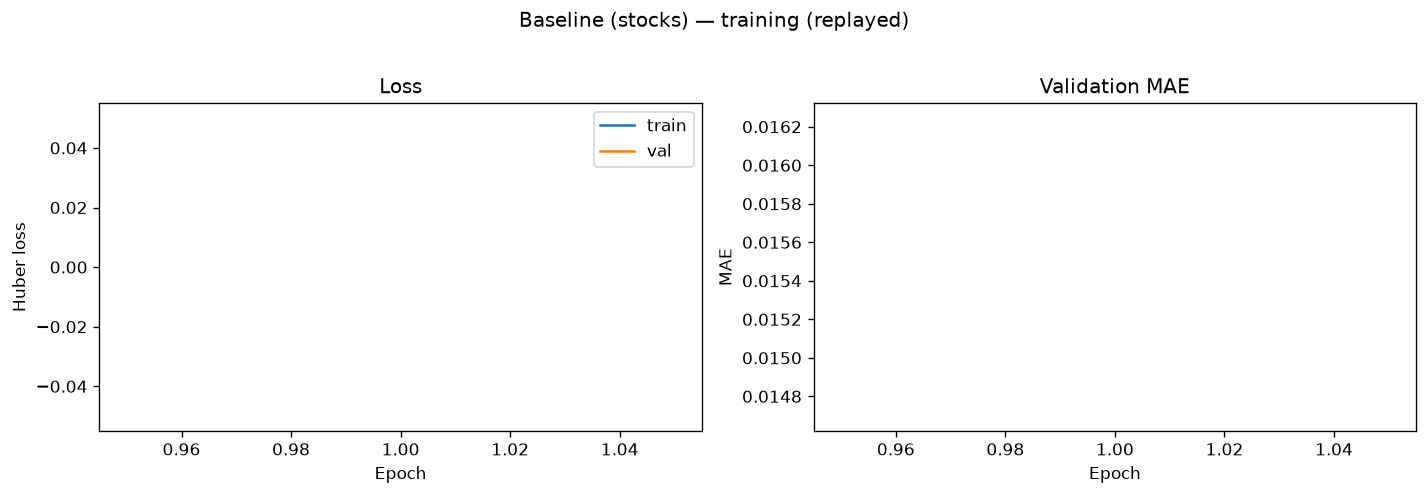

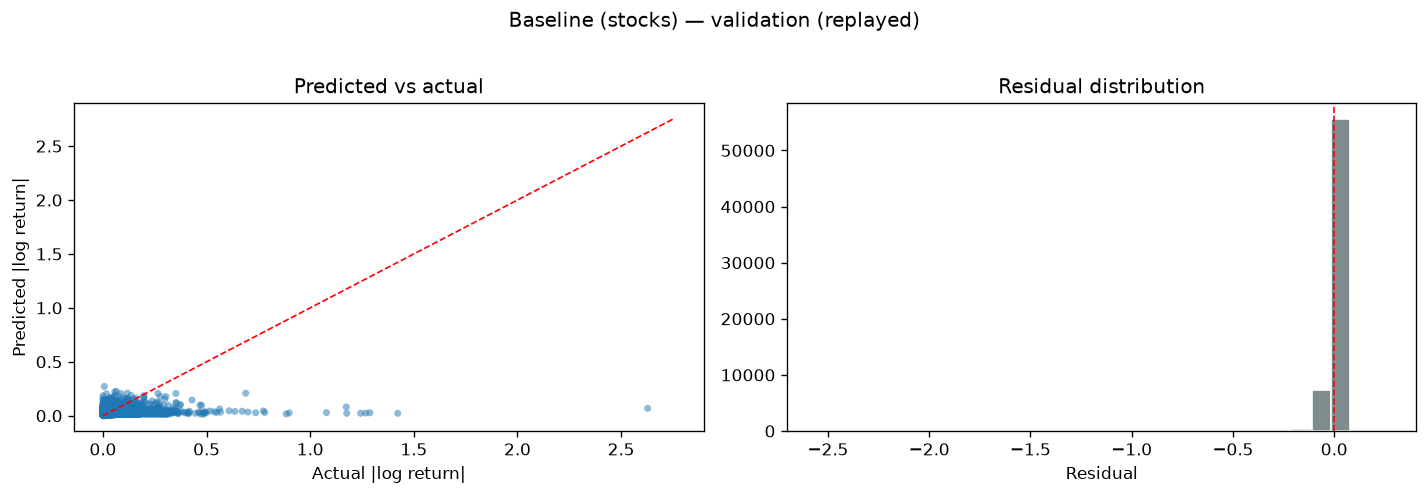

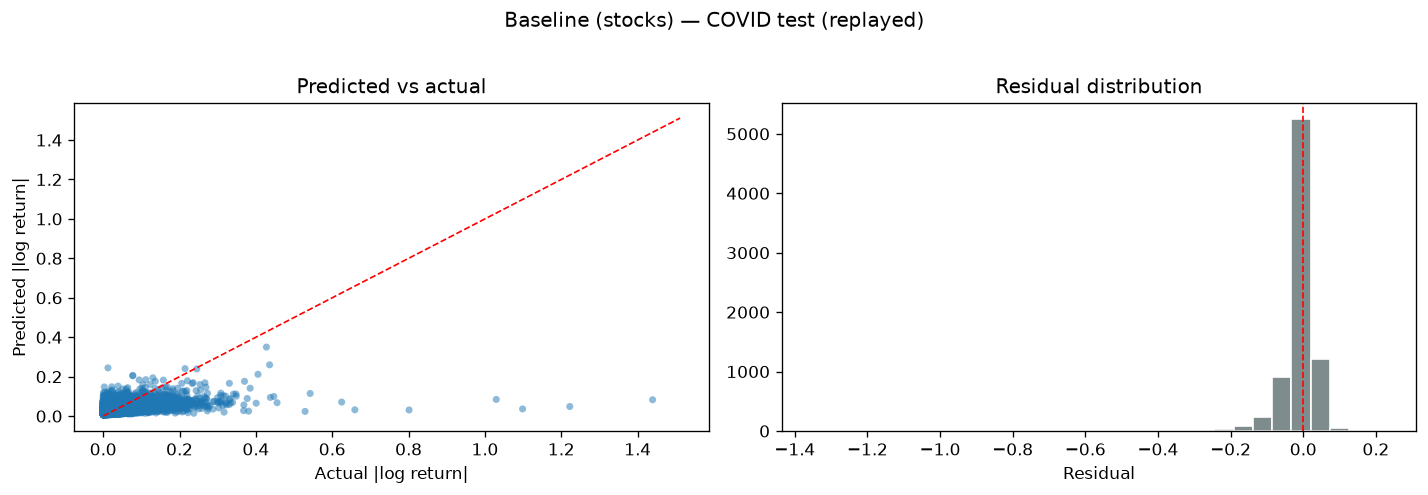

            Model  Val MAE  Crisis MAE  Val RMSE
Baseline (stocks) 0.015471    0.026955  0.031537
Persistence (val) 0.019687    0.035009       NaN
Train-mean (test) 0.017906    0.032017       NaN


In [1]:
hist_df = pd.DataFrame(
    {
        "epoch": np.arange(1, len(history.history["loss"]) + 1),
        "train_loss": history.history["loss"],
        "val_loss": history.history["val_loss"],
        "val_mae": history.history["val_mae"],
    }
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_df["epoch"], hist_df["train_loss"], label="train")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], label="val")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Huber loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(hist_df["epoch"], hist_df["val_mae"], color="#2980b9")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE")
axes[1].set_title("Validation MAE")
fig.suptitle("Baseline (stocks) — training", y=1.02)
plt.tight_layout()
plt.show()

def plot_predictions(y_true: np.ndarray, y_pred: np.ndarray, title: str) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(y_true, y_pred, alpha=0.5, s=18, edgecolors="none")
    lim = max(float(np.max(y_true)), float(np.max(y_pred))) * 1.05
    axes[0].plot([0, lim], [0, lim], "r--", lw=1)
    axes[0].set_xlabel("Actual |log return|")
    axes[0].set_ylabel("Predicted |log return|")
    axes[0].set_title("Predicted vs actual")
    resid = y_pred - y_true
    axes[1].hist(resid, bins=30, color="#7f8c8d", edgecolor="white")
    axes[1].axvline(0, color="red", ls="--", lw=1)
    axes[1].set_xlabel("Residual")
    axes[1].set_title("Residual distribution")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

plot_predictions(y_val, val_pred, "Baseline (stocks) — validation")
plot_predictions(y_test, test_pred, "Baseline (stocks) — COVID test")

table = pd.DataFrame(
    [
        {
            "Model": "Baseline (stocks)",
            "Val MAE": val_mae,
            "Crisis MAE": test_mae,
            "Val RMSE": val_rmse,
        },
        {
            "Model": "Persistence (val)",
            "Val MAE": persistence_mae_val,
            "Crisis MAE": persistence_mae_test,
            "Val RMSE": np.nan,
        },
        {
            "Model": "Train-mean (test)",
            "Val MAE": train_mean_mae_val,
            "Crisis MAE": train_mean_mae_test,
            "Val RMSE": np.nan,
        },
    ]
)
display(table)


## 6) Save model and prediction artifacts

Save TensorFlow model files and JSON metrics/predictions for cross-platform comparison.

In [7]:
artifact_stem = f"baseline_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}_tf"
best_model_path = MODELS_DIR / f"{artifact_stem}_best.joblib"
final_model_path = MODELS_DIR / f"{artifact_stem}_final.joblib"
pred_path = MODELS_DIR / f"{artifact_stem}_predictions.json"

model.save(best_model_path)
model.save(final_model_path)

payload = {
    "job_id": JOB_ID,
    "job_slug": JOB_SLUG,
    "architecture": ARCHITECTURE,
    "universe": UNIVERSE,
    "is_baseline": True,
    "model": f"baseline_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}",
    "run_mode": RUN_MODE,
    "dataset_tag": DATASET_TAG,
    "n_symbols": bundle.cfg.get("n_symbols"),
    "framework": getattr(model, "backend", "baseline"),
    "target_type": bundle.cfg["target_type"],
    "n_features": len(bundle.feature_cols),
    "lookback_days": bundle.cfg["lookback_days"],
    "feature_cols": bundle.feature_cols,
    "best_epoch": best_epoch,
    "best_val_mae": best_val_mae,
    "val_mae": val_mae,
    "val_rmse": val_rmse,
    "crisis_mae": test_mae,
    "test_rmse": test_rmse,

    "reference_baselines": {
        "persistence_mae_val": persistence_mae_val,
        "persistence_mae_test": persistence_mae_test,
        "train_mean_mae_val": train_mean_mae_val,
        "train_mean_mae_test": train_mean_mae_test,
        "beats_persistence_val": bool(val_mae < persistence_mae_val),
        "beats_persistence_test": bool(test_mae < persistence_mae_test),
    },
    "train_config": {
        "architecture": ARCHITECTURE,
        "task": TASK,
        "sequences_name": sequences_name,
    },
    "history": hist_df.to_dict(orient="records"),
    "predictions": {
        "val": {"y_true": y_val.tolist(), "y_pred": val_pred.tolist()},
        "test": {"y_true": y_test.tolist(), "y_pred": test_pred.tolist()},
    },
    "trained_at": datetime.now(timezone.utc).isoformat(),
}

with open(pred_path, "w") as f:
    json.dump(payload, f, indent=2)

print("Saved baseline artifacts:")
print(f"- {best_model_path}")
print(f"- {final_model_path}")
print(f"- {pred_path}")
print("Train 01a–01e models next; they compare against this baseline automatically.")


Saved baseline artifacts:
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/baseline_vol_risk_stocks_dev200_tf_best.joblib
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/baseline_vol_risk_stocks_dev200_tf_final.joblib
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/baseline_vol_risk_stocks_dev200_tf_predictions.json
Train 01a–01e models next; they compare against this baseline automatically.
